In [ ]:
from google.colab import files

uploaded = files.upload()

Saving DeepPCB-master.zip to DeepPCB-master (1).zip


In [ ]:
import zipfile
import os

zip_path = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

extract_path = "/content/DeepPCB"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)

    if level <= 3:
        indent = " " * 4 * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:5]:
            print(f"{indent}    {file}")

DeepPCB/
    DeepPCB-master/
        LICENSE
        README.md
        .gitignore
        evaluation/
            readme.txt
            rrc_evaluation_funcs.py
            gt.zip
            script.py
        tools/
            README.md
            PCBAnnotationTool/
                drawwidget.h
                src.qrc
                PCBAnnotationTool.pro
                datadef.h
                mainwindow.ui
            examples/
                test.txt
        PCBData/
            test.txt
            trainval.txt
            group44000/
            group92000/
            group13000/
            group12000/
            group90100/
            group12100/
            group50600/
            group00041/
            group20085/
            group12300/
            group77000/
        fig/
            CountPCB.png
            test.jpg
            template.jpg
            tools/
                PCBAnnotationSoftware.png
            result/
                result_temp1.jpg
           

In [ ]:
from collections import Counter

counts = Counter()

for root, dirs, files in os.walk(extract_path):
    for file in files:
        lower = file.lower()

        if lower.endswith((".jpg", ".jpeg", ".png")):
            counts["images"] += 1

        elif lower.endswith(".txt"):
            counts["annotations"] += 1

print("Total images:", counts["images"])
print("Total annotation files:", counts["annotations"])

Total images: 3021
Total annotation files: 1504


In [ ]:
import os
from collections import Counter

image_counts = Counter()

for root, dirs, files in os.walk(extract_path):
    for file in files:
        name = file.lower()

        if name.endswith((".jpg", ".jpeg", ".png")):
            if "_test" in name:
                image_counts["Test images"] += 1
            elif "_temp" in name:
                image_counts["Template images"] += 1
            else:
                image_counts["Other images"] += 1

print("IMAGE BREAKDOWN")
for category, count in image_counts.items():
    print(category, ":", count)

IMAGE BREAKDOWN
Other images : 6
Template images : 1508
Test images : 1507


In [ ]:
annotation_files = []

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.endswith(".txt"):
            annotation_files.append(
                os.path.join(root, file)
            )

print("Total annotation files:", len(annotation_files))

print("\nSample annotation files:")

for file in annotation_files[:5]:
    print("\nFile:", os.path.basename(file))

    with open(file, "r") as f:
        print(f.read()[:500])

Total annotation files: 1504

Sample annotation files:

File: readme.txt
INSTRUCTIONS FOR THE STANDALONE SCRIPTS
Requirements:
-         Python version 2.7.
-         Each Task requires different Python modules. When running the script, if some module is not installed you will see a notification and installation instructions.
 
Procedure:
Download the ZIP file for the requested script and unzip it to a directory.
 
Open a terminal in the directory and run the command:
python script.py –g=gt.zip –s=submit.zip
 
If you have already installed all the required modules, t

File: test.txt
/absolute/path/to/examples/grouptest/test/12100000.jpg /absolute/path/to/examples/grouptest/test_not/12100000.txt
/absolute/path/to/examples/grouptest/test/12100001.jpg /absolute/path/to/examples/grouptest/test_not/12100001.txt
/absolute/path/to/examples/grouptest/test/12100002.jpg /absolute/path/to/examples/grouptest/test_not/12100002.txt

File: test.txt
group20085/20085/20085291.jpg group20085/20085_not/2

In [ ]:
test_files = set()
template_files = set()
annotation_ids = set()

for root, dirs, files in os.walk(extract_path):
    for file in files:

        lower = file.lower()

        if lower.endswith((".jpg", ".jpeg", ".png")):

            if "_test." in lower:
                test_files.add(file.rsplit("_test.", 1)[0])

            elif "_temp." in lower:
                template_files.add(file.rsplit("_temp.", 1)[0])

        elif lower.endswith(".txt"):
            annotation_ids.add(os.path.splitext(file)[0])

print("Test images:", len(test_files))
print("Template images:", len(template_files))
print("Annotations:", len(annotation_ids))

print("\nMissing templates:",
      len(test_files - template_files))

print("Missing annotations:",
      len(test_files - annotation_ids))

Test images: 1500
Template images: 1501
Annotations: 1503

Missing templates: 0
Missing annotations: 0


In [ ]:
!pip install -q ultralytics PyYAML

import os
import shutil
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image, ImageDraw
from collections import Counter

import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Existing extracted dataset
extract_path = "/content/DeepPCB"

ROOT = Path(extract_path)

assert ROOT.exists(), "Dataset folder not found!"

print("Dataset directory:", ROOT)

GPU Available: False
Dataset directory: /content/DeepPCB


In [ ]:
excluded = {"examples", "evaluation", "tools", ".git"}

trainval_candidates = [
    p for p in ROOT.rglob("trainval.txt")
    if not any(
        part.lower() in excluded
        for part in p.relative_to(ROOT).parts[:-1]
    )
]

print("Training list candidates:")

for p in trainval_candidates:
    print(p)

assert len(trainval_candidates) == 1, (
    "Expected one main trainval.txt. "
    "Inspect the candidates and select the correct file manually."
)

TRAINVAL_LIST = trainval_candidates[0]
TEST_LIST = TRAINVAL_LIST.parent / "test.txt"

assert TEST_LIST.exists(), "Corresponding test.txt not found!"

print("\nTraining list:", TRAINVAL_LIST)
print("Testing list:", TEST_LIST)

Training list candidates:
/content/DeepPCB/DeepPCB-master/PCBData/trainval.txt

Training list: /content/DeepPCB/DeepPCB-master/PCBData/trainval.txt
Testing list: /content/DeepPCB/DeepPCB-master/PCBData/test.txt


In [ ]:
def resolve_file(relative_path, base_dir):
    p = Path(relative_path)

    # Generate possible candidates for file names on disk (adding _test or _temp suffixes for images)
    stem = p.stem
    suffix = p.suffix

    name_candidates = [p.name]
    if suffix.lower() in [".jpg", ".jpeg", ".png"]:
        name_candidates.extend([
            f"{stem}_test{suffix}",
            f"{stem}_temp{suffix}"
        ])

    # Try to resolve relative to the base directory and ROOT
    for name in name_candidates:
        for base in [base_dir, ROOT, ROOT / "DeepPCB-master" / "PCBData"]:
            candidate = base / p.parent / name
            if candidate.exists() and candidate.is_file():
                return candidate.resolve()

    # Fallback search inside the entire dataset directory
    for name in name_candidates:
        matches = list(ROOT.rglob(name))
        if matches:
            return matches[0].resolve()

    return None


def load_split(list_file):
    records = []
    missing = []

    for line in list_file.read_text().splitlines():
        parts = line.strip().split()
        if len(parts) < 2:
            continue

        image_path = resolve_file(
            parts[0], list_file.parent
        )
        annotation_path = resolve_file(
            parts[1], list_file.parent
        )

        if image_path is None or annotation_path is None:
            missing.append(line)
            continue

        records.append({
            "image": image_path,
            "annotation": annotation_path
        })

    print(f"\nList: {list_file.name}")
    print("Valid records:", len(records))
    print("Missing records:", len(missing))

    if missing:
        print("First missing entries:", missing[:3])

    return records


trainval_records = load_split(TRAINVAL_LIST)
test_records = load_split(TEST_LIST)

assert len(trainval_records) > 0
assert len(test_records) > 0

print("\nTotal usable records:",
      len(trainval_records) + len(test_records))


List: trainval.txt
Valid records: 1000
Missing records: 0

List: test.txt
Valid records: 500
Missing records: 0

Total usable records: 1500


In [ ]:
CLASS_NAMES = [
    "open",
    "short",
    "mousebite",
    "spur",
    "copper",
    "pin-hole"
]


def read_annotations(annotation_path, image_width, image_height):

    boxes = []
    invalid = 0

    with open(annotation_path, "r") as f:

        for line in f:

            values = line.replace(",", " ").split()

            if len(values) != 5:
                invalid += 1
                continue

            try:
                x1, y1, x2, y2, class_id = map(float, values)
                class_id = int(class_id)

            except ValueError:
                invalid += 1
                continue

            if class_id < 1 or class_id > 6:
                invalid += 1
                continue

            # Keep coordinates within image boundaries
            x1 = np.clip(x1, 0, image_width)
            x2 = np.clip(x2, 0, image_width)
            y1 = np.clip(y1, 0, image_height)
            y2 = np.clip(y2, 0, image_height)

            if x2 <= x1 or y2 <= y1:
                invalid += 1
                continue

            xc = ((x1 + x2) / 2) / image_width
            yc = ((y1 + y2) / 2) / image_height

            width = (x2 - x1) / image_width
            height = (y2 - y1) / image_height

            boxes.append([
                class_id - 1,
                xc,
                yc,
                width,
                height
            ])

    return boxes, invalid


class_counts = Counter()
total_boxes = 0
invalid_boxes = 0
empty_annotations = 0

all_records = trainval_records + test_records

for record in all_records:

    with Image.open(record["image"]) as img:
        width, height = img.size

    boxes, invalid = read_annotations(
        record["annotation"], width, height
    )

    invalid_boxes += invalid

    if not boxes:
        empty_annotations += 1

    for box in boxes:
        class_counts[int(box[0])] += 1
        total_boxes += 1


print("TOTAL ANNOTATED DEFECTS:", total_boxes)
print("INVALID BOXES:", invalid_boxes)
print("EMPTY ANNOTATIONS:", empty_annotations)

print("\nDEFECT DISTRIBUTION")

for i, name in enumerate(CLASS_NAMES):
    print(name, ":", class_counts[i])

TOTAL ANNOTATED DEFECTS: 10013
INVALID BOXES: 0
EMPTY ANNOTATIONS: 0

DEFECT DISTRIBUTION
open : 1942
short : 1506
mousebite : 1965
spur : 1625
copper : 1474
pin-hole : 1501


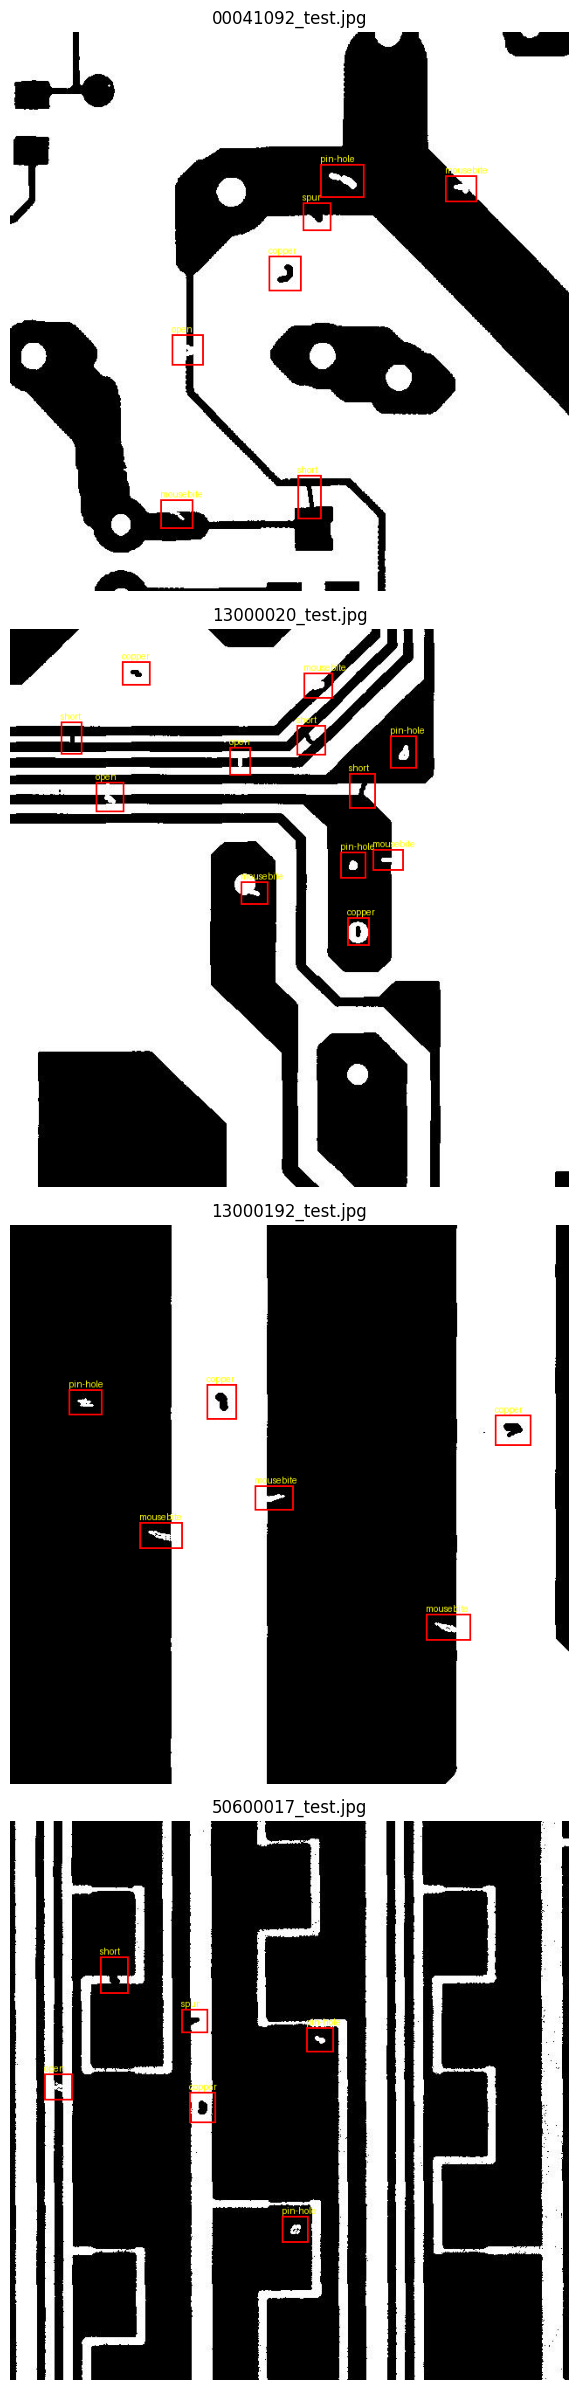

In [ ]:
def visualize_samples(records, number=4):

    samples = random.sample(
        records,
        min(number, len(records))
    )

    fig, axes = plt.subplots(
        len(samples), 1,
        figsize=(10, 6 * len(samples))
    )

    if len(samples) == 1:
        axes = [axes]

    for ax, record in zip(axes, samples):

        img = Image.open(record["image"]).convert("RGB")

        width, height = img.size

        draw = ImageDraw.Draw(img)

        boxes, _ = read_annotations(
            record["annotation"], width, height
        )

        for box in boxes:

            cls, xc, yc, bw, bh = box

            x1 = int((xc - bw / 2) * width)
            y1 = int((yc - bh / 2) * height)

            x2 = int((xc + bw / 2) * width)
            y2 = int((yc + bh / 2) * height)

            draw.rectangle(
                [x1, y1, x2, y2],
                outline="red",
                width=2
            )

            draw.text(
                (x1, max(0, y1 - 12)),
                CLASS_NAMES[int(cls)],
                fill="yellow"
            )

        ax.imshow(img)
        ax.set_title(record["image"].name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


visualize_samples(trainval_records, number=4)

In [ ]:
from sklearn.model_selection import train_test_split

random.seed(42)

train_records, val_records = train_test_split(
    trainval_records,
    test_size=0.20,
    random_state=42
)

OUTPUT = Path("/content/deeppcb_yolo")

for split in ["train", "val", "test"]:

    (OUTPUT / "images" / split).mkdir(
        parents=True, exist_ok=True
    )

    (OUTPUT / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )


def convert_records(records, split):

    successful = 0
    failed = 0

    for index, record in enumerate(records):

        try:

            image_path = record["image"]
            annotation_path = record["annotation"]

            with Image.open(image_path) as img:
                width, height = img.size

            boxes, invalid = read_annotations(
                annotation_path, width, height
            )

            # Give each image a unique output filename
            filename = f"{index:05d}_{image_path.name}"

            output_image = (
                OUTPUT / "images" / split / filename
            )

            output_label = (
                OUTPUT / "labels" / split /
                (Path(filename).stem + ".txt")
            )

            shutil.copy2(image_path, output_image)

            with open(output_label, "w") as f:

                for box in boxes:

                    f.write(
                        f"{int(box[0])} "
                        f"{box[1]:.6f} "
                        f"{box[2]:.6f} "
                        f"{box[3]:.6f} "
                        f"{box[4]:.6f}\n"
                    )

            successful += 1

        except Exception as e:

            failed += 1
            print("Error:", image_path, e)

    print(
        split,
        "Successful:", successful,
        "Failed:", failed
    )


convert_records(train_records, "train")
convert_records(val_records, "val")
convert_records(test_records, "test")

train Successful: 800 Failed: 0
val Successful: 200 Failed: 0
test Successful: 500 Failed: 0


In [ ]:
import yaml

dataset_config = {
    "path": str(OUTPUT),

    "train": "images/train",
    "val": "images/val",
    "test": "images/test",

    "names": {
        i: name for i, name in enumerate(CLASS_NAMES)
    }
}

yaml_path = OUTPUT / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.dump(dataset_config, f, sort_keys=False)

print(yaml_path.read_text())

path: /content/deeppcb_yolo
train: images/train
val: images/val
test: images/test
names:
  0: open
  1: short
  2: mousebite
  3: spur
  4: copper
  5: pin-hole



In [ ]:
for split in ["train", "val", "test"]:

    image_dir = OUTPUT / "images" / split
    label_dir = OUTPUT / "labels" / split

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))

    missing_labels = [
        img.name for img in images
        if not (label_dir / (img.stem + ".txt")).exists()
    ]

    print("\n", split.upper())
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Missing labels:", len(missing_labels))


 TRAIN
Images: 800
Labels: 800
Missing labels: 0

 VAL
Images: 200
Labels: 200
Missing labels: 0

 TEST
Images: 500
Labels: 500
Missing labels: 0


In [ ]:
from ultralytics import YOLO
import torch

model = YOLO("yolo11n.pt")

device = 0 if torch.cuda.is_available() else "cpu"

results = model.train(

    data=str(yaml_path),

    epochs=2,

    imgsz=640,

    batch=16 if torch.cuda.is_available() else 4,

    patience=15,

    workers=2,

    device=device,

    project="/content/PCB_Defect_Detection",

    name="YOLO11n_DeepPCB",

    seed=42,

    plots=True,

    save=True

)

Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (AMD EPYC 7B12)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/deeppcb_yolo/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11n_DeepPCB-2, nbs=64, nms=None, opset=None, optimize=False, o

In [ ]:
best_model_path = (
    Path(results.save_dir) /
    "weights" /
    "best.pt"
)

print("Best model:", best_model_path)

best_model = YOLO(str(best_model_path))

test_metrics = best_model.val(
    data=str(yaml_path),
    split="test",
    imgsz=640,
    batch=8 if torch.cuda.is_available() else 2,
    device=device,
    plots=True
)

print("\nPCB DEFECT DETECTION PERFORMANCE")
print("----------------------------------")

print("Precision:", test_metrics.box.mp)
print("Recall:", test_metrics.box.mr)
print("mAP50:", test_metrics.box.map50)
print("mAP50-95:", test_metrics.box.map)

Best model: /content/PCB_Defect_Detection/YOLO11n_DeepPCB-2/weights/best.pt
Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (AMD EPYC 7B12)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 4.1±2.2 MB/s, size: 36.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/deeppcb_yolo/labels/test... 500 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 500/500 726.0it/s 0.7s
val: New cache created: /content/deeppcb_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 250/250 3.1it/s 1:22
                   all        500       3140      0.673       0.65      0.678       0.33
                  open        482        659      0.711      0.548      0.621      0.279
                 short        36

In [ ]:
test_image_dir = OUTPUT / "images" / "test"

predictions = best_model.predict(
    source=str(test_image_dir),
    conf=0.25,
    save=True,
    project="/content/PCB_Predictions",
    name="results"
)

print("Prediction completed!")


image 1/500 /content/deeppcb_yolo/images/test/00000_20085291_test.jpg: 640x640 2 opens, 2 shorts, 2 spurs, 1 copper, 1 pin-hole, 134.5ms
image 2/500 /content/deeppcb_yolo/images/test/00001_20085292_test.jpg: 640x640 3 opens, 4 shorts, 2 spurs, 1 copper, 122.9ms
image 3/500 /content/deeppcb_yolo/images/test/00002_20085293_test.jpg: 640x640 2 opens, 4 shorts, 2 spurs, 1 pin-hole, 123.0ms
image 4/500 /content/deeppcb_yolo/images/test/00003_20085294_test.jpg: 640x640 3 opens, 4 shorts, 1 mousebite, 2 spurs, 2 coppers, 210.4ms
image 5/500 /content/deeppcb_yolo/images/test/00004_20085295_test.jpg: 640x640 4 opens, 7 shorts, 1 copper, 242.6ms
image 6/500 /content/deeppcb_yolo/images/test/00005_20085296_test.jpg: 640x640 3 opens, 2 shorts, 2 spurs, 1 copper, 1 pin-hole, 183.1ms
image 7/500 /content/deeppcb_yolo/images/test/00006_20085297_test.jpg: 640x640 1 open, 1 short, 1 mousebite, 5 spurs, 124.5ms
image 8/500 /content/deeppcb_yolo/images/test/00007_20085298_test.jpg: 640x640 3 shorts, 1 m

00456_12300218_test.jpg


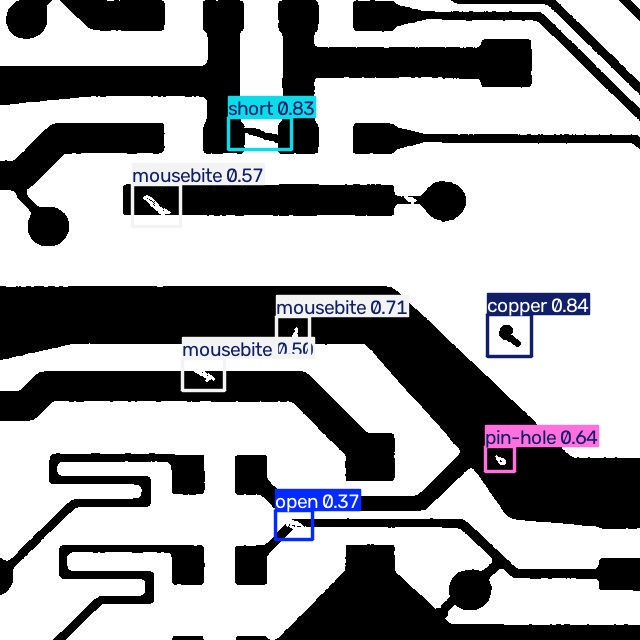

00363_12100176_test.jpg


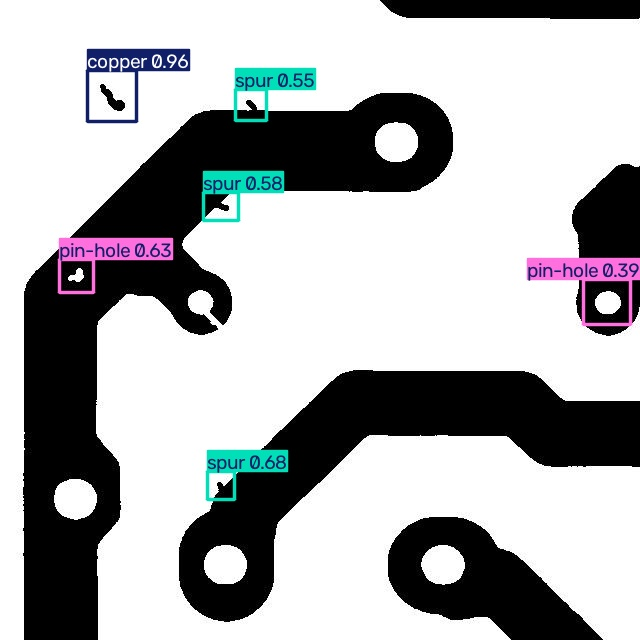

00085_92000116_test.jpg


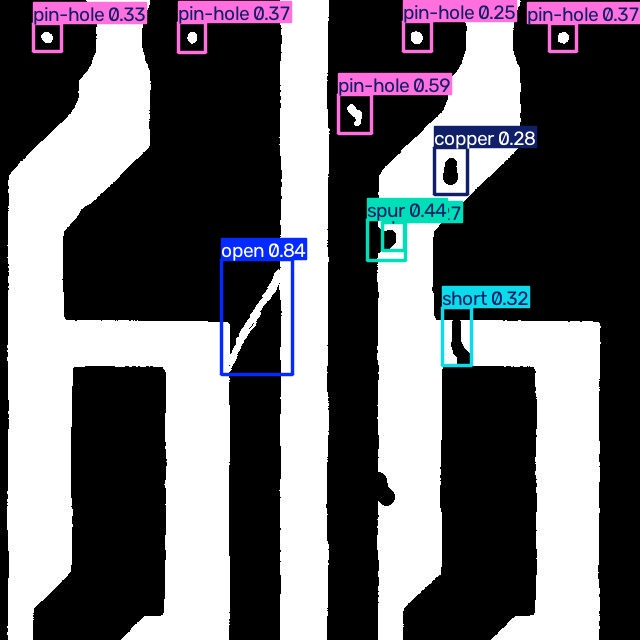

00178_90100011_test.jpg


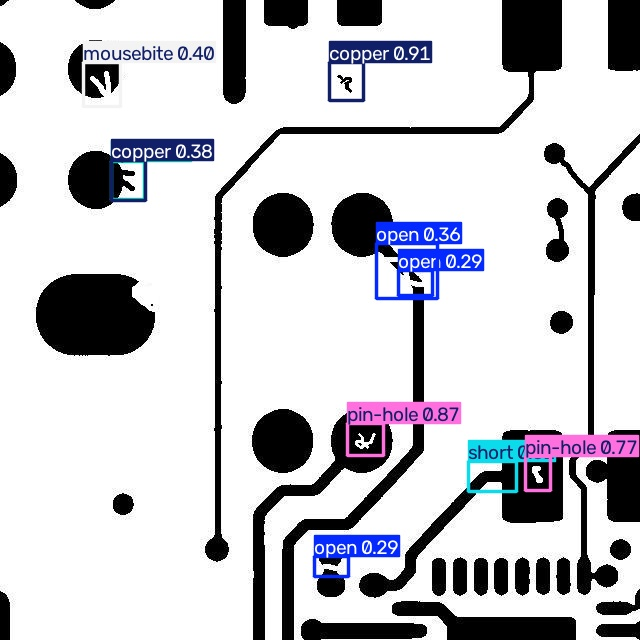

00118_44000011_test.jpg


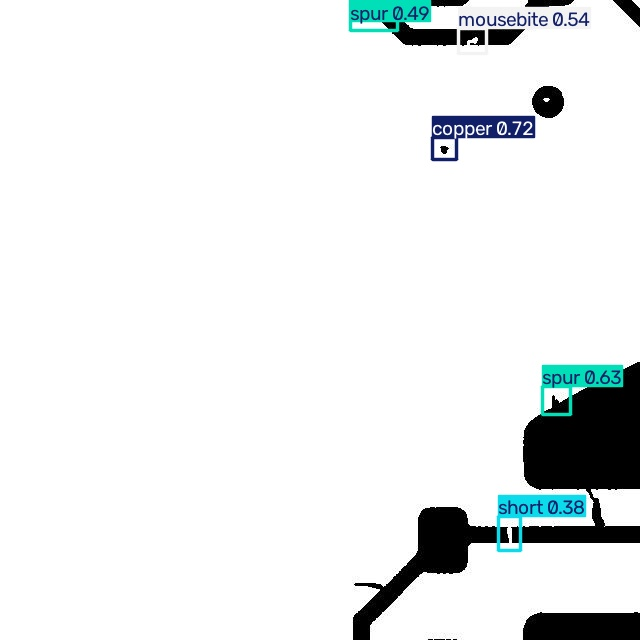

In [ ]:
from IPython.display import display

prediction_folder = Path(
    "/content/PCB_Predictions/results"
)

predicted_images = list(
    prediction_folder.glob("*.jpg")
)

for image_path in predicted_images[:5]:

    print(image_path.name)
    display(Image.open(image_path))

In [ ]:
import json

final_model_path = "/content/pcb_defect_detection_best.pt"

shutil.copy2(
    best_model_path,
    final_model_path
)

performance_report = {

    "industry": "Electronics and Electrical",

    "application": "PCB Defect Detection and Localization",

    "architecture": "YOLO11n",

    "classes": CLASS_NAMES,

    "precision": float(test_metrics.box.mp),

    "recall": float(test_metrics.box.mr),

    "mAP50": float(test_metrics.box.map50),

    "mAP50_95": float(test_metrics.box.map)

}

with open(
    "/content/pcb_defect_performance.json", "w"
) as f:

    json.dump(performance_report, f, indent=4)

print("Model and performance report saved!")
print(final_model_path)

Model and performance report saved!
/content/pcb_defect_detection_best.pt
